# Akuisisi Data Akomodasi di Kecamatan Kintamani
**BIFP-243 Akuisisi dan Manajemen Data** · Tugas praktik individu

Sumber data: OpenStreetMap melalui Overpass API · Pembanding: BPS Kabupaten Bangli.
Data © OpenStreetMap contributors (lisensi ODbL).

**Cara pakai:** isi semua bagian bertanda **ISI MANUAL**, lalu jalankan dari atas ke bawah (Runtime > Run all).
Query ke Overpass hanya dijalankan sekali; kalau berkas mentah sudah ada, sel akuisisi memakainya lagi
(supaya IP bersama di Colab tidak kena batas 429).

## 1. Setup
Mengimpor library, menyiapkan identitas (ubah hanya di satu tempat), membuat struktur folder,
dan menghubungkan Google Drive supaya berkas tidak hilang saat sesi Colab berakhir.

In [9]:
import hashlib
import json
import shutil
import time
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import requests

# ===== ISI MANUAL: identitas (cukup ubah di sini) =====
NIM = "2501010089"
NAMA = "I Made Bagus Abiyoga Prawira"
# ======================================================

NAMA_PROYEK = f"akomodasi_kintamani_{NIM}"
BASE = Path("/content") / NAMA_PROYEK          # folder kerja (lokal Colab)



for sub in ["data/raw", "data/interim", "notebooks", "docs", "reports"]:
    (BASE / sub).mkdir(parents=True, exist_ok=True)


def sinkron_ke_drive():
    """Salin seluruh folder proyek ke Google Drive (aman dipanggil berulang)."""
    if DRIVE_BASE is None:
        print("Drive tidak tersedia, dilewati.")
        return
    shutil.copytree(BASE, DRIVE_BASE, dirs_exist_ok=True)
    print("Tersalin ke Drive:", DRIVE_BASE)


print("Folder kerja:", BASE)
print(sorted(str(p.relative_to(BASE)) for p in BASE.rglob("*") if p.is_dir()))

Folder kerja: /content/akomodasi_kintamani_2501010089
['data', 'data/interim', 'data/raw', 'docs', 'notebooks', 'reports']


## 2a. Query Overpass
**ISI MANUAL:** buka overpass-turbo.eu, jalankan query di bawah, dan pastikan batas wilayahnya benar-benar
Kecamatan Kintamani (nama "Kintamani" bisa merujuk ke kecamatan atau desa; cek `admin_level`).
Jika batas administratif tidak cocok, ubah `PAKAI_BBOX = True` dan isi koordinat kotak wilayah.
Jenis akomodasi yang dimasukkan ke query juga perlu kamu putuskan dan jelaskan di laporan
(villa di OSM biasanya diberi tag `guest_house`, `chalet`, atau `apartment`).

In [10]:
URL = "https://overpass-api.de/api/interpreter"
HEADERS = {"User-Agent": f"INSTIKI-BIFP243-Praktikum/1.0 ({NIM}@instiki.ac.id)"}

# ISI MANUAL: sesuaikan daftar jenis kalau perlu (dan jelaskan alasannya di laporan)
JENIS_REGEX = "^(hotel|guest_house|hostel|motel|apartment|chalet)$"

# Opsi A: batas administratif (default dari lembar tugas)
QUERY_ADMIN = f"""[out:json][timeout:90];
area["name"="Kintamani"]["boundary"="administrative"]["admin_level"="6"]->.kec;
nwr["tourism"~"{JENIS_REGEX}"](area.kec);
out center tags;"""


QUERY_BBOX = f"""[out:json][timeout:90];
nwr["tourism"~"{JENIS_REGEX}"]({BBOX_SELATAN},{BBOX_BARAT},{BBOX_UTARA},{BBOX_TIMUR});
out center tags;"""

if PAKAI_BBOX:
    assert None not in (BBOX_SELATAN, BBOX_BARAT, BBOX_UTARA, BBOX_TIMUR), "Isi koordinat bounding box dulu"
    QUERY = QUERY_BBOX
else:
    QUERY = QUERY_ADMIN

(BASE / "docs/query_overpass.txt").write_text(QUERY, encoding="utf-8")
print(QUERY)

[out:json][timeout:90];
area["name"="Kintamani"]["boundary"="administrative"]["admin_level"="6"]->.kec;
nwr["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"](area.kec);
out center tags;


## 2b. Akuisisi dari Overpass API
Fungsi `ambil_overpass()` mencoba maksimal 4 kali dengan jeda awal 5 detik yang dikali 2 tiap gagal
(exponential backoff), timeout 120 detik, dan menangani status 429 (terlalu banyak request),
504 (server sibuk), serta `Timeout`/`ConnectionError`. Respons mentah disimpan **tanpa diubah** di `data/raw/`.

Kalau Overpass bermasalah: tunggu dan jalankan sel ini lagi di lain waktu, lalu catat kendalanya di laporan.

In [11]:
def ambil_overpass(query, maks_percobaan=4, jeda=5):
    """Kirim query ke Overpass dengan retry dan exponential backoff."""
    for percobaan in range(1, maks_percobaan + 1):
        try:
            r = requests.post(URL, data={"data": query}, headers=HEADERS, timeout=120)
            if r.status_code == 200:
                return r.json()
            print(f"[percobaan {percobaan}] status {r.status_code}, tunggu {jeda}s")
        except (requests.Timeout, requests.ConnectionError) as e:
            print(f"[percobaan {percobaan}] {type(e).__name__}, tunggu {jeda}s")
        time.sleep(jeda)
        jeda *= 2
    raise RuntimeError("Gagal mengambil data dari Overpass. Tunggu lalu coba lagi nanti.")


# Hindari request berulang: kalau berkas mentah sudah ada, pakai yang terbaru
FORCE_DOWNLOAD = False
berkas_ada = sorted((BASE / "data/raw").glob("osm_akomodasi_kintamani_*.json"))

if berkas_ada and not FORCE_DOWNLOAD:
    raw_path = berkas_ada[-1]
    data = json.loads(raw_path.read_text(encoding="utf-8"))
    waktu_akuisisi_utc = datetime.fromtimestamp(raw_path.stat().st_mtime, tz=timezone.utc).isoformat()
    print("Memakai berkas mentah yang sudah ada:", raw_path.name)
else:
    waktu_akuisisi_utc = datetime.now(timezone.utc).isoformat()
    data = ambil_overpass(QUERY)
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    raw_path = BASE / f"data/raw/osm_akomodasi_kintamani_{stamp}.json"
    raw_path.write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")
    print("Respons mentah disimpan:", raw_path.name)

print("Jumlah elemen:", len(data["elements"]))

# Definisikan DRIVE_BASE jika belum ada untuk mencegah NameError
if 'DRIVE_BASE' not in globals():
    DRIVE_BASE = None



Respons mentah disimpan: osm_akomodasi_kintamani_20261111_103311.json
Jumlah elemen: 32


## 3. Catatan provenance
Mencatat asal data: endpoint, query, waktu akuisisi (UTC), jumlah elemen, nama berkas mentah + hash MD5,
lisensi, dan identitas pengambil. Hash MD5 membuktikan berkas mentah tidak berubah setelah disimpan.

In [8]:
def hitung_md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for blok in iter(lambda: f.read(8192), b""):
            h.update(blok)
    return h.hexdigest()


provenance = {
    "url_endpoint": URL,
    "query": QUERY,
    "waktu_akuisisi_utc": waktu_akuisisi_utc,
    "jumlah_elemen": len(data["elements"]),
    "berkas_mentah": raw_path.name,
    "md5_berkas_mentah": hitung_md5(raw_path),
    "lisensi": "ODbL 1.0 - (c) OpenStreetMap contributors",
    "pengambil": {"nama": NAMA, "nim": NIM},
}

(BASE / "docs/provenance.json").write_text(
    json.dumps(provenance, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(json.dumps(provenance, ensure_ascii=False, indent=2))

{
  "url_endpoint": "https://overpass-api.de/api/interpreter",
  "query": "[out:json][timeout:90];\narea[\"name\"=\"Kintamani\"][\"boundary\"=\"administrative\"][\"admin_level\"=\"6\"]->.kec;\nnwr[\"tourism\"~\"^(hotel|guest_house|hostel|motel|apartment|chalet)$\"](area.kec);\nout center tags;",
  "waktu_akuisisi_utc": "2026-11-11T10:29:57.050920+00:00",
  "jumlah_elemen": 32,
  "berkas_mentah": "osm_akomodasi_kintamani_20261111_102957.json",
  "md5_berkas_mentah": "a92b7ebee7efa2e7e088107a0ff1ffa7",
  "lisensi": "ODbL 1.0 - (c) OpenStreetMap contributors",
  "pengambil": {
    "nama": "ISI_NAMA_KAMU",
    "nim": "ISI_NIM_KAMU"
  }
}


## 4. Meratakan respons menjadi tabel
Setiap elemen (titik, bangunan, atau relasi) diubah menjadi satu baris. Nomor telepon, email, dan akun
media sosial **sengaja tidak diambil** (minimisasi data). `bintang` dan `jumlah_kamar` dibiarkan bertipe teks
karena isian relawan OSM tidak selalu angka.

In [12]:
KOLOM = ["osm_type", "osm_id", "nama", "jenis", "lat", "lon",
         "desa", "bintang", "jumlah_kamar", "website", "url_osm"]


def ratakan(elements):
    baris = []
    for e in elements:
        tg = e.get("tags", {})
        pusat = e.get("center", e)   # node: lat/lon langsung; way/relation: di "center"
        baris.append({
            "osm_type": e["type"],
            "osm_id": e["id"],
            "nama": tg.get("name"),
            "jenis": tg.get("tourism"),
            "lat": pusat.get("lat"),
            "lon": pusat.get("lon"),
            "desa": tg.get("addr:village"),
            "bintang": tg.get("stars"),
            "jumlah_kamar": tg.get("rooms"),
            "website": tg.get("website") or tg.get("contact:website"),
            "url_osm": f"https://www.openstreetmap.org/{e['type']}/{e['id']}",
        })
    return pd.DataFrame(baris, columns=KOLOM)


akomodasi = ratakan(data["elements"])
print("Baris:", len(akomodasi), "| Elemen mentah:", len(data["elements"]))
print(akomodasi["jenis"].value_counts())
print("Tanpa nama:", akomodasi["nama"].isna().sum())
akomodasi.head()

Baris: 32 | Elemen mentah: 32
jenis
hotel          16
guest_house     9
hostel          4
chalet          2
motel           1
Name: count, dtype: int64
Tanpa nama: 1


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,None,None,None,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907
1,node,2107226701,Arlina,guest_house,-8.249815,115.398465,None,None,None,None,https://www.openstreetmap.org/node/2107226701
2,node,2107227001,Toya Devasya Resort,hotel,-8.250164,115.399798,None,None,None,None,https://www.openstreetmap.org/node/2107227001
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,None,None,None,None,https://www.openstreetmap.org/node/4150326329
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,None,2,5,None,https://www.openstreetmap.org/node/4297310696


## 5. Pemeriksaan kualitas data
Memeriksa duplikat, nama kosong, koordinat di luar wilayah, dan kolom yang hampir selalu kosong.
Tidak ada data yang dihapus diam-diam: setiap keputusan dicatat di daftar `keputusan` dan disimpan
ke `docs/keputusan_kualitas.csv` untuk bahan laporan.

**ISI MANUAL:** batas koordinat di bawah hanya perkiraan kasar. Sesuaikan dengan kotak wilayah Kintamani
yang kamu lihat di overpass-turbo.

In [13]:
# ISI MANUAL: perkiraan kotak wilayah Kintamani (sesuaikan dengan hasil cek di peta)
LAT_MIN, LAT_MAX = -8.35, -8.05
LON_MIN, LON_MAX = 115.25, 115.50

df = akomodasi.copy()
keputusan = []

# 1) Duplikat berdasarkan osm_type + osm_id
n_dup = int(df.duplicated(subset=["osm_type", "osm_id"]).sum())
if n_dup > 0:
    df = df.drop_duplicates(subset=["osm_type", "osm_id"], keep="first")
    keputusan.append(("duplikat", n_dup, "dihapus, simpan kemunculan pertama"))
else:
    keputusan.append(("duplikat", 0, "tidak ada, tidak ada yang dihapus"))

# 2) Nama kosong (dipertahankan, hanya dihitung)
n_noname = int(df["nama"].isna().sum())
keputusan.append(("nama_kosong", n_noname, "dipertahankan, dihitung dan dilaporkan"))

# 3) Koordinat kosong atau di luar wilayah (ditandai, tidak dihapus)
n_koord_null = int(df[["lat", "lon"]].isna().any(axis=1).sum())
di_luar = df[(df["lat"] < LAT_MIN) | (df["lat"] > LAT_MAX) | (df["lon"] < LON_MIN) | (df["lon"] > LON_MAX)]
keputusan.append(("koordinat_kosong", n_koord_null, "dipertahankan, perlu dicek manual"))
keputusan.append(("koordinat_di_luar_kotak", len(di_luar), "dipertahankan, perlu dicek manual di peta"))
if len(di_luar):
    print("Koordinat di luar kotak (cek manual):")
    print(di_luar[["osm_type", "osm_id", "nama", "lat", "lon", "url_osm"]].to_string(index=False))

# 4) Kolom hampir selalu kosong
persen_kosong = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print("\nPersentase kosong per kolom (%):")
print(persen_kosong)
for kol, p in persen_kosong.items():
    if p >= 90:
        keputusan.append((f"kolom_hampir_kosong:{kol}", float(p), "dipertahankan sesuai struktur dataset, dicatat di laporan"))

# 5) Pastikan tidak ada kolom data kontak
terlarang = [c for c in df.columns if any(k in c.lower() for k in ["phone", "telp", "email", "contact", "facebook", "instagram"])]
assert not terlarang, f"Ada kolom kontak: {terlarang}"

# 6) Distribusi jenis dan desa
print("\nJumlah per jenis:")
per_jenis = df["jenis"].value_counts()
print(per_jenis)
print("\nJumlah per desa:")
per_desa = df["desa"].fillna("(tidak diisi)").value_counts()
print(per_desa)

# Simpan dataset dan catatan keputusan (data/raw tidak disentuh)
df[KOLOM].to_csv(BASE / "data/interim/akomodasi_kintamani.csv", index=False, encoding="utf-8")
ket = pd.DataFrame(keputusan, columns=["pemeriksaan", "jumlah_atau_persen", "keputusan"])
ket.to_csv(BASE / "docs/keputusan_kualitas.csv", index=False, encoding="utf-8")
print("\nDataset akhir:", len(df), "baris")
ket


Persentase kosong per kolom (%):
desa            100.0
bintang          96.9
jumlah_kamar     93.8
website          93.8
nama              3.1
osm_id            0.0
osm_type          0.0
lon               0.0
lat               0.0
jenis             0.0
url_osm           0.0
dtype: float64

Jumlah per jenis:
jenis
hotel          16
guest_house     9
hostel          4
chalet          2
motel           1
Name: count, dtype: int64

Jumlah per desa:
desa
(tidak diisi)    32
Name: count, dtype: int64

Dataset akhir: 32 baris


,pemeriksaan,jumlah_atau_persen,keputusan
0,duplikat,0.0,"tidak ada, tidak ada yang dihapus"
1,nama_kosong,1.0,"dipertahankan, dihitung dan dilaporkan"
2,koordinat_kosong,0.0,"dipertahankan, perlu dicek manual"
3,koordinat_di_luar_kotak,0.0,"dipertahankan, perlu dicek manual di peta"
4,kolom_hampir_kosong:desa,100.0,"dipertahankan sesuai struktur dataset, dicatat..."
5,kolom_hampir_kosong:bintang,96.9,"dipertahankan sesuai struktur dataset, dicatat..."
6,kolom_hampir_kosong:jumlah_kamar,93.8,"dipertahankan sesuai struktur dataset, dicatat..."
7,kolom_hampir_kosong:website,93.8,"dipertahankan sesuai struktur dataset, dicatat..."


## 6. Peta sebaran sederhana
Plot titik koordinat berwarna menurut jenis akomodasi. Disimpan sebagai PNG di `reports/` untuk laporan.

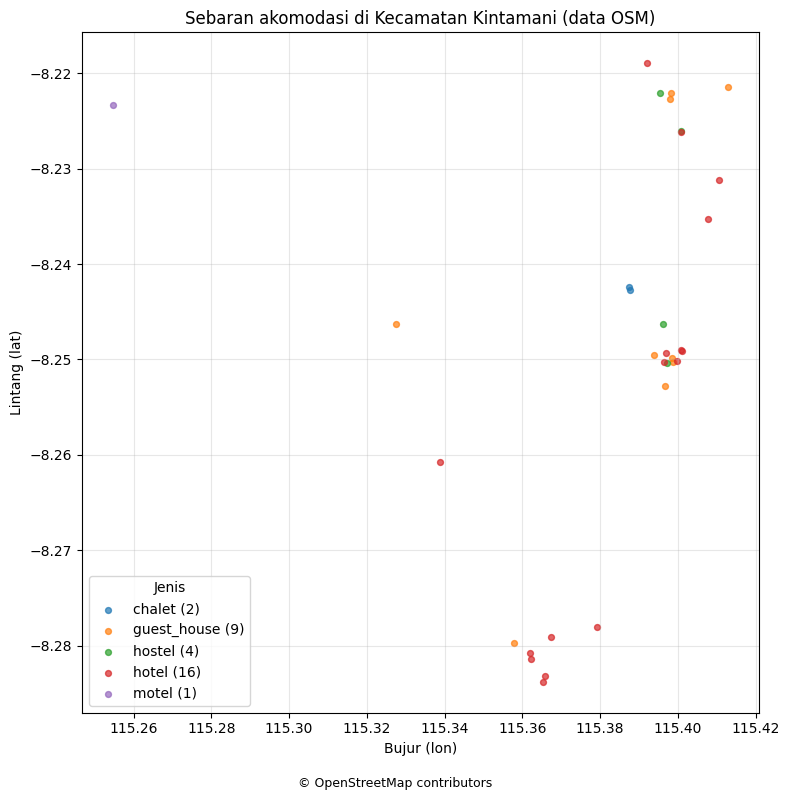

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8))
for jenis, grup in df.dropna(subset=["lat", "lon"]).groupby("jenis"):
    ax.scatter(grup["lon"], grup["lat"], s=18, alpha=0.7, label=f"{jenis} ({len(grup)})")

ax.set_xlabel("Bujur (lon)")
ax.set_ylabel("Lintang (lat)")
ax.set_title("Sebaran akomodasi di Kecamatan Kintamani (data OSM)")
ax.legend(title="Jenis")
ax.grid(alpha=0.3)
fig.text(0.5, 0.01, "\u00a9 OpenStreetMap contributors", ha="center", fontsize=9)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(BASE / "reports/peta_sebaran_kintamani.png", dpi=150)
plt.show()

## 7. Uji kelengkapan terhadap BPS
**ISI MANUAL:** cari jumlah akomodasi Kecamatan Kintamani di BPS Kabupaten Bangli (mis. *Kecamatan Kintamani
Dalam Angka* atau *Bangli Dalam Angka*) atau portal Satu Data Bali. Isi angkanya, tahun data, dan sumbernya.
Jika angka per kecamatan tidak ditemukan, biarkan `BPS_JUMLAH = None` dan jelaskan di `CATATAN_BPS`;
penjelasan itu wajib masuk laporan.

Rumus: kelengkapan = jumlah OSM ÷ jumlah BPS × 100%.

In [21]:
# ===== ISI MANUAL =====
BPS_JUMLAH = 205
BPS_TAHUN = 2024

CATATAN_BPS = "DATA OSN MENCANGKUP 15.6 DARI TOTAL DAFTAR BPS KINTAMANI"

BPS_SUMBER = "BPS KINTAMANI"

# Opsional: rincian BPS per kategori -> (jumlah BPS, jenis OSM yang setara)
BPS_RINCIAN = {
    # "Hotel bintang": (0, ["hotel"]),
    # "Hotel non-bintang / akomodasi lainnya": (0, ["guest_house", "hostel", "motel", "apartment", "chalet"]),
}
# ======================

osm_total = len(df)
baris = []


def tambah_baris(level, kategori, osm, bps):
    persen = round(osm / bps * 100, 1) if bps else None
    baris.append({
        "level": level,
        "kategori": kategori,
        "jumlah_osm": osm,
        "jumlah_bps": bps,
        "kelengkapan_persen": persen,
        "tahun_bps": BPS_TAHUN,
        "sumber_bps": BPS_SUMBER,
        "catatan": CATATAN_BPS,
    })
    return persen


# --- Validasi input ---
if BPS_JUMLAH is not None:
    assert isinstance(BPS_JUMLAH, (int, float)) and BPS_JUMLAH > 0, "BPS_JUMLAH harus angka > 0"
    assert BPS_TAHUN is not None, "Isi BPS_TAHUN (tahun data BPS wajib disebut)"

# --- Total ---
persen_total = tambah_baris("total", "semua akomodasi", osm_total, BPS_JUMLAH)

if BPS_JUMLAH is None:
    print("Angka BPS belum ditemukan/diisi.")
    if not CATATAN_BPS.strip():
        print("PERINGATAN: isi CATATAN_BPS, penjelasannya wajib masuk laporan.")
else:
    print(f"Total  | OSM: {osm_total} | BPS ({BPS_TAHUN}): {BPS_JUMLAH:g} | Kelengkapan: {persen_total}%")
    if persen_total > 100:
        print("PERINGATAN: kelengkapan > 100%. Cek apakah definisi akomodasi OSM dan BPS sama "
              "(mis. BPS hanya mencatat usaha terdaftar) dan jelaskan di laporan.")

# --- Per kategori (opsional) ---
if BPS_RINCIAN:
    jumlah_rincian = sum(b for b, _ in BPS_RINCIAN.values())
    if BPS_JUMLAH is not None and jumlah_rincian != BPS_JUMLAH:
        print(f"PERINGATAN: jumlah rincian ({jumlah_rincian:g}) tidak sama dengan total BPS ({BPS_JUMLAH:g}).")
    for kategori, (bps_k, jenis_osm) in BPS_RINCIAN.items():
        osm_k = int(df["jenis"].isin(jenis_osm).sum())
        p = tambah_baris("kategori", kategori, osm_k, bps_k)
        print(f"{kategori} | OSM: {osm_k} | BPS: {bps_k:g} | Kelengkapan: {p}%")
    # jenis OSM yang tidak masuk kategori BPS mana pun (bahan analisis "apa yang terlewat")
    terpetakan = {j for _, jl in BPS_RINCIAN.values() for j in jl}
    lainnya = df[~df["jenis"].isin(terpetakan)]["jenis"].value_counts()
    if len(lainnya):
        print("Jenis OSM di luar kategori BPS:", lainnya.to_dict())

banding = pd.DataFrame(baris)
banding.to_csv(BASE / "docs/perbandingan_bps.csv", index=False, encoding="utf-8")
banding

Total  | OSM: 32 | BPS (2024): 205 | Kelengkapan: 15.6%


,level,kategori,jumlah_osm,jumlah_bps,kelengkapan_persen,tahun_bps,sumber_bps,catatan
0,total,semua akomodasi,32,205,15.6,2024,BPS KINTAMANI,DATA OSN MENCANGKUP 15.6 DARI TOTAL DAFTAR BPS...


## 8. Sampel verifikasi 10 data
Mengambil 10 data acak (`random_state` tetap agar hasilnya sama setiap dijalankan). **ISI MANUAL:** buka
situs resmi akomodasi atau peta untuk tiap baris, lalu isi `terverifikasi` (ya/tidak/sebagian) dan `catatan`
(nama, jenis, dan lokasinya benar atau tidak) di berkas CSV-nya. Situs resmi hanya untuk memeriksa manual,
bukan untuk diambil otomatis.

In [22]:
sampel = df.sample(n=min(10, len(df)), random_state=42)[["nama", "jenis", "lat", "lon", "desa", "url_osm"]].copy()
sampel["terverifikasi"] = "iya"   # ISI MANUAL: ya / tidak / sebagian
sampel["catatan"] = ""         # ISI MANUAL: apa yang cocok atau berbeda
sampel.to_csv(BASE / "docs/sampel_verifikasi_10.csv", index=False, encoding="utf-8")
sampel

,nama,jenis,lat,lon,desa,url_osm,terverifikasi,catatan
29,Batur Sunrise Guesthouse,hotel,-8.249020,115.400863,None,https://www.openstreetmap.org/node/13068182153,iya,
15,Caldera,hotel,-8.279139,115.367364,None,https://www.openstreetmap.org/node/6451134585,iya,
24,Bunbulan Panorama Villas,guest_house,-8.222736,115.397971,None,https://www.openstreetmap.org/node/9769685089,iya,
17,Segara Hotel,hotel,-8.278086,115.379134,None,https://www.openstreetmap.org/node/7058054537,iya,
8,The Volcania Guesthouse,hotel,-8.283796,115.365242,None,https://www.openstreetmap.org/node/5065920543,iya,
9,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,None,https://www.openstreetmap.org/node/5175562421,iya,
30,Lava Bali and Hot Spring,hotel,-8.250311,115.396374,None,https://www.openstreetmap.org/node/13284479326,iya,
25,Villa Jempana,hotel,-8.231158,115.410556,None,https://www.openstreetmap.org/node/9778735917,iya,
12,Hut,chalet,-8.242693,115.387587,None,https://www.openstreetmap.org/node/5479746121,iya,
0,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,None,https://www.openstreetmap.org/node/1977779907,iya,


## 9. Dokumentasi otomatis
Membuat `data_dictionary.csv`, kerangka `data_ethics_checklist.csv`, dan `README.md`.
Kolom checklist bertanda **ISI MANUAL** perlu kamu lengkapi dengan bukti nyata sebelum dikumpulkan.

In [23]:
# ---- Data dictionary ----
data_dictionary = pd.DataFrame([
    ["osm_type", "teks", "Jenis objek OSM: node, way, atau relation", "way", "Tidak"],
    ["osm_id", "bilangan bulat", "ID objek di OpenStreetMap", "123456789", "Tidak"],
    ["nama", "teks", "Nama akomodasi sesuai tag name", "(nama akomodasi)", "Ya, wajib dihitung jumlahnya"],
    ["jenis", "teks", "Nilai tag tourism", "guest_house", "Tidak"],
    ["lat", "desimal", "Lintang titik atau titik tengah bangunan (WGS84)", "-8.27", "Tidak"],
    ["lon", "desimal", "Bujur titik atau titik tengah bangunan (WGS84)", "115.37", "Tidak"],
    ["desa", "teks", "Desa sesuai tag addr:village", "(nama desa)", "Ya"],
    ["bintang", "teks", "Klasifikasi bintang (tag stars)", "3", "Ya"],
    ["jumlah_kamar", "teks", "Jumlah kamar (tag rooms)", "20", "Ya"],
    ["website", "teks", "Situs resmi akomodasi", "https://...", "Ya"],
    ["url_osm", "teks", "Tautan ke objek di openstreetmap.org untuk pengecekan", "https://www.openstreetmap.org/way/...", "Tidak"],
], columns=["kolom", "tipe", "deskripsi", "contoh", "boleh_kosong"])
data_dictionary.to_csv(BASE / "docs/data_dictionary.csv", index=False, encoding="utf-8")

# ---- Data Ethics Checklist (kerangka; lengkapi bukti) ----
checklist = pd.DataFrame([
    ["Sumber data hanya yang diizinkan (OSM Overpass, BPS)", "Ya", "Lihat docs/provenance.json (endpoint overpass-api.de)"],
    ["Tidak memakai OTA/platform pemesanan atau halaman Google Maps", "Ya", "Tidak ada kode request ke situs tersebut di notebook"],
    ["Lisensi ODbL dicatat dan atribusi OSM dicantumkan", "Ya", "README.md, laporan, dan keterangan peta"],
    ["Batas pemakaian API dihormati (query 1-2 kali, ada retry/backoff)", "Ya", "Fungsi ambil_overpass; berkas mentah dipakai ulang"],
    ["User-Agent mengidentifikasi pengambil data", "Ya", "Variabel HEADERS di notebook"],
    ["Tidak mengambil data kontak pribadi (telepon, email, media sosial)", "Ya", "Fungsi ratakan tidak mengambil tag tersebut; ada assert di sel kualitas"],
    ["Berkas data/raw tidak diubah setelah disimpan", "Ya", "Hash MD5 di provenance.json"],
    ["Setiap keputusan pembersihan dicatat, tidak ada penghapusan diam-diam", "Ya", "docs/keputusan_kualitas.csv"],
    ["Kendala server Overpass (jika ada) dilaporkan", "ISI MANUAL", "ISI MANUAL: tulis kendala yang terjadi, atau 'tidak ada'"],
    ["Verifikasi 10 sampel dilakukan manual (bukan otomatis)", "ISI MANUAL", "docs/sampel_verifikasi_10.csv yang sudah kamu isi"],
], columns=["item", "status", "bukti"])
checklist.to_csv(BASE / "docs/data_ethics_checklist.csv", index=False, encoding="utf-8")

# ---- README ----
README = f"""# Akuisisi Data Akomodasi di Kecamatan Kintamani

Tugas praktik BIFP-243 Akuisisi dan Manajemen Data.
Pengambil data: {NAMA} ({NIM})

## Tujuan
Mengakuisisi data akomodasi (hotel, guest house, villa, dan sejenisnya) di Kecamatan Kintamani secara etis,
menyimpan respons mentah, mengubahnya menjadi dataset tabular terdokumentasi, dan menilai kelengkapannya
terhadap angka resmi BPS.

## Sumber data
- OpenStreetMap melalui Overpass API ({URL}), lisensi ODbL.
- Pembanding: BPS Kabupaten Bangli ({BPS_SUMBER}, tahun {BPS_TAHUN}).

## Tanggal akses
{waktu_akuisisi_utc} (UTC)

## Metode akuisisi
Query Overpass (lihat docs/query_overpass.txt) dikirim dengan Python (requests) dengan timeout dan retry
exponential backoff. Respons mentah disimpan apa adanya di data/raw/, lalu diratakan menjadi
data/interim/akomodasi_kintamani.csv. Jumlah elemen: {len(data["elements"])}; baris dataset akhir: {len(df)}.

## Batasan etika
- Tidak memakai situs OTA, platform pemesanan, maupun halaman Google Maps.
- Tidak mengambil data kontak pribadi (telepon, email, media sosial).
- Batas pemakaian API dihormati; query dijalankan sangat terbatas.
- Data OSM diisi relawan sehingga tidak lengkap; hasilnya tidak boleh dianggap sensus akomodasi.

## Atribusi
Data (c) OpenStreetMap contributors, tersedia di bawah lisensi ODbL.

## Cara menjalankan ulang
1. Buka notebooks/akuisisi_akomodasi.ipynb di Google Colab.
2. Isi NIM dan NAMA di sel Setup.
3. Hapus berkas di data/raw/ (atau set FORCE_DOWNLOAD = True) kalau ingin mengambil data baru.
4. Runtime > Run all.
"""
(BASE / "README.md").write_text(README, encoding="utf-8")

print("Dokumen dibuat:", sorted(p.name for p in (BASE / "docs").glob("*")) + ["README.md"])
checklist

Dokumen dibuat: ['data_dictionary.csv', 'data_ethics_checklist.csv', 'keputusan_kualitas.csv', 'perbandingan_bps.csv', 'query_overpass.txt', 'sampel_verifikasi_10.csv', 'README.md']


,item,status,bukti
0,Sumber data hanya yang diizinkan (OSM Overpass...,Ya,Lihat docs/provenance.json (endpoint overpass-...
1,Tidak memakai OTA/platform pemesanan atau hala...,Ya,Tidak ada kode request ke situs tersebut di no...
2,Lisensi ODbL dicatat dan atribusi OSM dicantumkan,Ya,"README.md, laporan, dan keterangan peta"
3,"Batas pemakaian API dihormati (query 1-2 kali,...",Ya,Fungsi ambil_overpass; berkas mentah dipakai u...
4,User-Agent mengidentifikasi pengambil data,Ya,Variabel HEADERS di notebook
5,"Tidak mengambil data kontak pribadi (telepon, ...",Ya,Fungsi ratakan tidak mengambil tag tersebut; a...
6,Berkas data/raw tidak diubah setelah disimpan,Ya,Hash MD5 di provenance.json
7,"Setiap keputusan pembersihan dicatat, tidak ad...",Ya,docs/keputusan_kualitas.csv
8,Kendala server Overpass (jika ada) dilaporkan,ISI MANUAL,"ISI MANUAL: tulis kendala yang terjadi, atau '..."
9,Verifikasi 10 sampel dilakukan manual (bukan o...,ISI MANUAL,docs/sampel_verifikasi_10.csv yang sudah kamu isi


## 10. Kerangka laporan (3-5 halaman)
Sel ini menyiapkan `reports/kerangka_laporan.md` berisi tabel ringkasan otomatis dan poin pengarah.
Salin ke Word/Docs, lengkapi dengan penjelasanmu sendiri, sisipkan peta dari `reports/peta_sebaran_kintamani.png`,
lalu ekspor menjadi `reports/laporan_akomodasi_kintamani.pdf`.

Bagian refleksi (150-200 kata) **hanya berisi poin pengarah**; tulislah dengan kata-katamu sendiri.

In [24]:
def ke_md(tabel):
    try:
        return tabel.to_markdown()
    except Exception:
        return tabel.to_string()


kerangka = f"""# Laporan Akuisisi Data Akomodasi Kecamatan Kintamani
{NAMA} - {NIM}

## 1. Ringkasan dataset
Jumlah akomodasi: {len(df)} (dari {len(data["elements"])} elemen mentah).

Per jenis:
{ke_md(per_jenis.rename("jumlah"))}

Per desa:
{ke_md(per_desa.rename("jumlah"))}

(ISI MANUAL: jelaskan jenis yang kamu masukkan ke query dan alasannya, termasuk soal villa.)

## 2. Peta sebaran
Sisipkan reports/peta_sebaran_kintamani.png. Keterangan: (c) OpenStreetMap contributors.

## 3. Uji kelengkapan dan verifikasi sampel
- Jumlah OSM: {jumlah_osm}; BPS: {BPS_JUMLAH} (tahun {BPS_TAHUN}); kelengkapan: {kelengkapan}%.
- (ISI MANUAL: jika angka BPS per kecamatan tidak ditemukan, jelaskan di sini.)
- Verifikasi 10 sampel: (ISI MANUAL: ringkas hasil dari docs/sampel_verifikasi_10.csv, berapa yang benar.)

## 4. Masalah kualitas data dan keputusan
{ke_md(ket)}

(ISI MANUAL: kendala server Overpass jika ada, dan alasan tiap keputusan.)

## 5. Refleksi (150-200 kata, tulis sendiri)
Poin pengarah:
- OSM diisi relawan: akomodasi baru atau kecil mungkin belum dipetakan.
- Apakah jenis tertentu (mis. homestay/villa kecil) paling sering terlewat, dan apa buktinya di datamu?
- Tag seperti nama, stars, dan rooms sering kosong atau tidak seragam.
- Selisih dengan angka BPS: bedanya cakupan, definisi akomodasi, dan tahun data.
- Sumber tambahan untuk riset lanjutan yang diizinkan (data pemda/dinas pariwisata, survei lapangan,
  data resmi lain), tanpa melanggar ketentuan layanan platform.

(c) OpenStreetMap contributors
"""
(BASE / "reports/kerangka_laporan.md").write_text(kerangka, encoding="utf-8")
print(kerangka[:1500])

# Laporan Akuisisi Data Akomodasi Kecamatan Kintamani
I Made Bagus Abiyoga Prawira - 2501010089

## 1. Ringkasan dataset
Jumlah akomodasi: 32 (dari 32 elemen mentah).

Per jenis:
| jenis       |   jumlah |
|:------------|---------:|
| hotel       |       16 |
| guest_house |        9 |
| hostel      |        4 |
| chalet      |        2 |
| motel       |        1 |

Per desa:
| desa          |   jumlah |
|:--------------|---------:|
| (tidak diisi) |       32 |

(ISI MANUAL: jelaskan jenis yang kamu masukkan ke query dan alasannya, termasuk soal villa.)

## 2. Peta sebaran
Sisipkan reports/peta_sebaran_kintamani.png. Keterangan: (c) OpenStreetMap contributors.

## 3. Uji kelengkapan dan verifikasi sampel
- Jumlah OSM: 32; BPS: 205 (tahun 2024); kelengkapan: None%.
- (ISI MANUAL: jika angka BPS per kecamatan tidak ditemukan, jelaskan di sini.)
- Verifikasi 10 sampel: (ISI MANUAL: ringkas hasil dari docs/sampel_verifikasi_10.csv, berapa yang benar.)

## 4. Masalah kualitas data dan keput